# 1 · Data Engineering: Landing → Bronze → Silver → Gold

| ชั้น | เก็บอะไร | เครื่องมือ |
|---|---|---|
| Landing | ไฟล์ดิบตามที่ดึงมา (HTML / JSON / CSV) + `_manifest.csv` | requests + BeautifulSoup |
| Bronze | แปลงเป็นตาราง Parquet แต่ทุกคอลัมน์ยังเป็น string ไม่แก้ค่า | pandas → Parquet |
| Silver | แปลงชนิดข้อมูล ทำความสะอาด ทำเครื่องหมายแถวที่มีปัญหา | PySpark |
| Gold | ตาราง fact / feature / profile พร้อมทำ dashboard และ ML | Spark SQL |

In [1]:
import os, sys, json
ROOT = os.path.abspath('..')
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import pandas as pd
pd.set_option('display.max_columns', 40, 'display.width', 200)
from IPython.display import Image, display

## Extraction log (ทุกคำขอที่ scrape)

In [2]:
m = pd.read_csv('lake/landing/_manifest.csv') if os.path.exists('lake/landing/_manifest.csv') else pd.DataFrame()
m.groupby(['source', 'status']).size().unstack(fill_value=0) if len(m) else 'manifest not present (landing/ is gitignored)'

status,200,ERR HTTPError
source,,
bma_flood,105,0
bma_open_data,6,0
bma_rain,112,0
holidays,1,0
metar,1,0
openmeteo,5,0
osm,2,2
sun,7,0


## Bronze: ตารางดิบ

In [3]:
import glob
for p in sorted(glob.glob('lake/bronze/*.parquet')):
    df = pd.read_parquet(p)
    print(f'{os.path.basename(p):32s} rows={len(df):>7,} cols={df.shape[1]}')

bma_flood.parquet                rows= 11,760 cols=10
bma_flood_risk.parquet           rows=    737 cols=19
bma_flood_risk26.parquet         rows=    216 cols=8
bma_flood_sensors.parquet        rows=    239 cols=47
bma_frd_dds.parquet              rows=    246 cols=20
bma_rain.parquet                 rows=  5,712 cols=16
bma_rain_stations.parquet        rows=    125 cols=18
cameras.parquet                  rows=    100 cols=10
holidays.parquet                 rows=     37 cols=7
images_index.parquet             rows= 61,319 cols=4
metar.parquet                    rows=    672 cols=12
openmeteo.parquet                rows= 16,800 cols=9
osm_poi.parquet                  rows= 10,952 cols=6
osm_roads.parquet                rows=  7,316 cols=4
sun.parquet                      rows=      7 cols=13


## Silver: Spark DataFrame + schema

In [4]:
from src.common.spark import spark
s = spark()
img = s.read.parquet('lake/silver/images.parquet')
img.printSchema()
img.groupBy('is_broken', 'is_frozen', 'is_valid').count().orderBy('count', ascending=False).show()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 22:19:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- path: string (nullable = true)
 |-- cam: integer (nullable = true)
 |-- bytes: long (nullable = true)
 |-- ts: timestamp_ntz (nullable = true)
 |-- location: string (nullable = true)
 |-- decode_ok: long (nullable = true)
 |-- width: long (nullable = true)
 |-- height: long (nullable = true)
 |-- brightness: double (nullable = true)
 |-- dhash: string (nullable = true)
 |-- is_broken: integer (nullable = true)
 |-- is_frozen: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- image_id: string (nullable = true)
 |-- is_valid: integer (nullable = true)



+---------+---------+--------+-----+
|is_broken|is_frozen|is_valid|count|
+---------+---------+--------+-----+
|        0|        0|       1|60235|
|        0|        1|       0|  580|
|        1|        0|       0|  504|
+---------+---------+--------+-----+



## Data quality rules (ทุกกฎและจำนวนแถวที่โดน)

In [5]:
pd.DataFrame(json.load(open('reports/dq_rules.json')))

,table,rule,rows_before,rows_affected,action
0,cameras,"english name placeholder (""connect BMAcctv""/""0...",100,5,set_null
1,cameras,coordinates missing or outside Bangkok bbox,100,0,flag
2,cameras,duplicate camera_id,100,0,drop
3,images,non-image entries in zip,61319,0,drop
4,images,filename does not match <cam>/<cam>_<loc>_<yyy...,61319,0,drop
5,images,timestamp outside study window 2026-08-25..202...,61319,0,drop
6,images,"duplicate (camera, timestamp)",61319,0,drop
7,images,camera id not in cctv_info,61319,0,drop
8,images,broken image (< 3000 bytes or cannot decode),61319,504,flag
9,images,stale frame: identical to previous frame of sa...,61319,580,flag


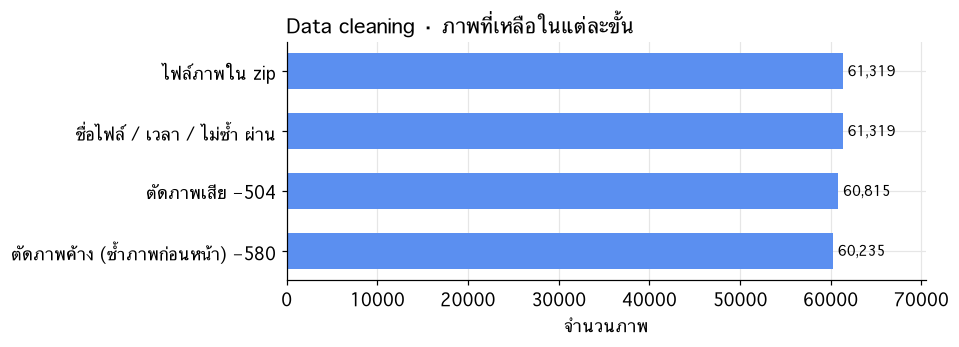

In [6]:
display(Image('reports/figures/dq_image_funnel.png'))

## Gold: Spark SQL

In [7]:
s.read.parquet('lake/gold/fact_images').createOrReplaceTempView('fact_images')
s.sql('''select day_type, rain_level, count(*) as images, round(avg(vehicles),2) as veh_mean
         from fact_images group by day_type, rain_level order by day_type, rain_level''').show()

+--------+----------+------+--------+
|day_type|rain_level|images|veh_mean|
+--------+----------+------+--------+
| weekday|       dry| 40509|    4.73|
| weekday|     heavy|    82|    4.41|
| weekday|     light|  1676|    3.12|
| weekday|   unknown|   250|    1.72|
| weekend|       dry| 14774|    3.56|
| weekend|     heavy|  1055|    4.33|
| weekend|     light|  1788|    4.31|
| weekend|   unknown|   101|    1.25|
+--------+----------+------+--------+



In [8]:
feat = pd.read_parquet('lake/gold/features_cam_hr.parquet')
print(feat.shape)
feat.head()

(10583, 49)


,cam,date,hour,period,dow,is_weekend,is_holiday,day_type,light,n_images,veh_mean,car_mean,moto_mean,bus_mean,truck_mean,cong_mean,rain_mm,rain_level,rain_prev_mm,rain_prev_level,...,station_dist_m,poi_mall,poi_market,poi_government,poi_office,poi_school,poi_rail_station,poi_bus_stop,poi_food,poi_hospital,dist_rail_m,highway,lanes_n,flood_points_500m,flood_unfixed_500m,flood_risk2568_500m,flood_events_2566_district,flood_kde,in_flood_hotspot,flood_hotspot_id
0,11,2026-08-25,6,เช้า,3,0,0,weekday,day,5,13.400000,8.00,0.000000,2.20,3.200000,1.200000,0.0,dry,0.0,dry,...,904.485809,2.0,2.0,0.0,0.0,2.0,0.0,4.0,18.0,5.0,443.904817,primary,2.0,0.0,0.0,0.0,29,0.44,0,-1
1,11,2026-08-25,7,เช้า,3,0,0,weekday,day,5,16.000000,10.60,0.000000,3.60,1.800000,1.062500,0.0,dry,0.0,dry,...,904.485809,2.0,2.0,0.0,0.0,2.0,0.0,4.0,18.0,5.0,443.904817,primary,2.0,0.0,0.0,0.0,29,0.44,0,-1
2,11,2026-08-25,8,เช้า,3,0,0,weekday,day,4,16.000000,10.25,0.000000,3.75,2.000000,1.062500,0.0,dry,0.0,dry,...,904.485809,2.0,2.0,0.0,0.0,2.0,0.0,4.0,18.0,5.0,443.904817,primary,2.0,0.0,0.0,0.0,29,0.44,0,-1
3,11,2026-08-25,9,สาย,3,0,0,weekday,day,6,14.666667,9.50,0.000000,3.00,2.166667,1.044444,0.0,dry,0.0,dry,...,904.485809,2.0,2.0,0.0,0.0,2.0,0.0,4.0,18.0,5.0,443.904817,primary,2.0,0.0,0.0,0.0,29,0.44,0,-1
4,11,2026-08-25,10,สาย,3,0,0,weekday,day,6,14.500000,9.00,0.166667,3.00,2.333333,1.107143,0.0,dry,0.0,dry,...,904.485809,2.0,2.0,0.0,0.0,2.0,0.0,4.0,18.0,5.0,443.904817,primary,2.0,0.0,0.0,0.0,29,0.44,0,-1
